# Geometry-selected hypothesis classes in a double data re-uploading classifier

We use a controlled SAR-like phase-history task to ask a structural question: when the acquisition geometry fixes one query encoding of a double data re-uploading circuit, does it select a hypothesis class $\mathcal H(f^\star_{\rm geom})$ that is aligned with the classification rule? Each sample is an $8\times8$ complex phase-history patch with a labeled point target in one of eight azimuth cells, off-range clutter, complex Gaussian noise and a fixed label-independent channel phase. The patch varies between samples while the acquisition and reference range are fixed, so $f^\star_{\rm geom}$ is a single architectural hyperparameter shared by the whole dataset.

The circuit alternates phase-only data uploads and fixed query gates with trainable blocks that never couple the azimuth and range registers, so the query cannot be absorbed into them. The figure shows (a) test accuracy across fixed queries $f/f^\star_{\rm geom}$ on identical data, (b) the validation-profile minimum $\widehat f$ against $f^\star_{\rm geom}$ for eight acquisitions, and (c) sample efficiency of the aligned query against a wrong-sign control $-f^\star_{\rm geom}$, an $x$-only circuit ($f=0$) and a trainable global query. A supplementary figure shows the mechanism with an untrained, calibrated readout.

**Outputs.** `figures/fig_08_double_reuploading_geometry.pdf` (and `.png`) — the three-panel figure; `figures/fig_08_double_reuploading_geometry_task.pdf` (and `.png`) — task and mechanism without fitted parameters; `results/sar_fixed_query/` — raw per-fit results, run configuration and the aggregated summary.

**Runtime.** With the cached results in `results/sar_fixed_query/` the notebook runs in under a minute. Recomputing from scratch takes several hours on a CPU (900 fits with 6 Adam restarts each): delete `results/sar_fixed_query/sar_fixed_query_paper_0033ff2273a7.csv`, or set `PROFILE = "smoke"` for a quick end-to-end check (its numbers are not paper results). Figure text is typeset with LaTeX, so a LaTeX installation is required.

## Setup

We import the numerical and plotting libraries and enable double precision in JAX.

In [1]:
from pathlib import Path
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

Results and figures are written to `results/sar_fixed_query/` and `figures/`. The plotting style matches the single-column layout of the figure, and each arm has a fixed color.

In [2]:
RESULTS_DIR = Path("../results/sar_fixed_query")
FIGURE_DIR = Path("../figures")
FIGURE_STEM = "fig_08_double_reuploading_geometry"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# single-column style; figure text is typeset with LaTeX
mpl.rcParams.update(
    {
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage{amssymb}",
        "font.family": "serif",
        "font.size": 8,
        "axes.labelsize": 7.0,
        "axes.titlesize": 7.5,
        "axes.linewidth": 0.6,
        "xtick.labelsize": 6.0,
        "ytick.labelsize": 6.0,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "lines.linewidth": 1.2,
        "legend.fontsize": 6.0,
        "figure.titlesize": 8,
    }
)
COLORS = {
    "aligned": "#E64B35",
    "mismatched": "#4DBBD5",
    "none": "#7E6148",
    "learned": "#3C5488",
    "geometry": "#00A087",
    "reference": "#4D4D4D",
}

## Configuration

`PROFILE` selects the cached paper statistics or a quick smoke check. The acquisition parameters describe an X-band-like local patch, and the scene parameters set the clutter, noise and jitter of the data model. Every setting below, together with the derived geometries, enters the configuration hash `RUN_ID` that names the cached results.

In [3]:
PROFILE = "paper"

# Two three-qubit registers: azimuth wavenumber and range wavenumber.
N = 3
Q = 2**N
NUM_QUBITS = 2 * N
DIM = Q * Q
LAYERS = 2

# X-band-like local acquisition patch. k_r is the two-way range wavenumber.
C0 = 299_792_458.0
CARRIER_HZ = 10.0e9
RANGE_FREQUENCY_STEP_HZ = 5.0e6
AZIMUTH_WAVENUMBER_CENTER = 125.0
AZIMUTH_WAVENUMBER_STEP = 1.25
REFERENCE_RANGE_M = 3700.0

# Controlled SAR-like scene model.
SNR_DB = 10.0
N_CLUTTER = 4
CLUTTER_RMS = 1.25
AZIMUTH_SUBCELL_JITTER = 0.48
CLUTTER_RANGE_RATIO = (0.45, 1.55)

# Fixed channel phase. It is learnable by the local trainable blocks but is
# not part of the geometry supplied to the circuit.
SENSOR_Z_PHASES = np.array([1.5, -1.7, 1.0])

PROFILES = {
    "smoke": dict(
        n_draws=2,
        geometry_profile_draws=1,
        geometry_profile_points=7,
        n_train_scan=128,
        n_validation=256,
        n_test=512,
        efficiency_ns=[64, 256],
        n_restarts=2,
        adam_steps=150,
        adam_lr=0.05,
        scan_points=7,
        bootstrap_samples=200,
    ),
    "paper": dict(
        n_draws=12,
        geometry_profile_draws=4,
        geometry_profile_points=15,
        n_train_scan=512,
        n_validation=1024,
        n_test=4096,
        efficiency_ns=[32, 64, 128, 256, 512],
        n_restarts=6,
        adam_steps=700,
        adam_lr=0.04,
        scan_points=15,
        bootstrap_samples=5000,
    ),
}
if PROFILE not in PROFILES:
    raise ValueError(f"unknown PROFILE={PROFILE!r}")
P = PROFILES[PROFILE]

EXPERIMENT_VERSION = "fixed-query-v3-profile-bootstrap"
BASE_SEED = 271828

print(
    f"profile={PROFILE} | {Q} classes | {LAYERS} re-uploading layers | "
    f"draws={P['n_draws']}"
)
if PROFILE != "paper":
    print("SMOKE PROFILE: its numerical values are not manuscript results.")

profile=paper | 8 classes | 2 re-uploading layers | draws=12


## Acquisition geometry and fixed query

For the sampled range frequencies and azimuth wavenumbers,

$$
k_{r,d}=\frac{4\pi}{c}\left[f_c+\left(d-\frac{Q-1}{2}\right)\Delta f_r\right],
\qquad
k_{x,a}=k_{x,0}+\left(a-\frac{Q-1}{2}\right)\Delta k_x .
$$

The $\omega$-$k$ surface is $k_{y,ad}=\sqrt{k_{r,d}^2-k_{x,a}^2}$. Terms that depend only on $a$ or only on $d$ are separable single-register phases; removing them leaves the interaction

$$
\widetilde k_{y,ad}=k_{y,ad}-\overline k_{y,a\cdot}-\overline k_{y,\cdot d}+\overline k_y .
$$

Around the patch center, with centered indices $\widetilde a$ and $\widetilde d$,

$$
\widetilde k_{y,ad}\simeq\kappa_{xr}\,\Delta k_x\Delta k_r\,\widetilde a\widetilde d,
\qquad
\kappa_{xr}=\left.\frac{\partial^2 k_y}{\partial k_x\partial k_r}\right|_0
=\frac{k_{x,0}k_{r,0}}{(k_{r,0}^2-k_{x,0}^2)^{3/2}} .
$$

A target at reference slant range $R_0$ therefore carries the leading nonseparable phase

$$
f^\star_{\rm geom}\,\widetilde a\widetilde d,
\qquad
f^\star_{\rm geom}=R_0\,\kappa_{xr}\,\Delta k_x\Delta k_r .
$$

All of these quantities are fixed before any scene or label is drawn, so $f^\star_{\rm geom}$ is not sample metadata: it selects one hypothesis class $\mathcal H(f^\star_{\rm geom})$ for the whole task. The circuit uses only the compact generator $\widetilde a\widetilde d$, whereas the scenes are generated from the full sampled interaction $H^{\rm exact}_{ad}=\widetilde k_{y,ad}/(\kappa_{xr}\Delta k_x\Delta k_r)$.

`build_geometry` samples the patch for one set of acquisition parameters and returns $\kappa_{xr}$, $f^\star_{\rm geom}$, $H^{\rm exact}$ and the quality of its bilinear fit. The compact generator $\widetilde a\widetilde d$ is shared by all acquisitions.

In [4]:
TWO_PI = 2 * np.pi
INDEX = np.arange(Q, dtype=float)
CENTERED = INDEX - (Q - 1) / 2
CELL_WIDTH = TWO_PI / Q

# compact interaction implemented by the query gate
H_COMPACT = np.outer(CENTERED, CENTERED)
H_COMPACT_FLAT = jnp.asarray(H_COMPACT.reshape(-1))
MAX_BILINEAR = float(np.max(np.abs(H_COMPACT)))


def build_geometry(
    carrier_hz=CARRIER_HZ,
    range_step_hz=RANGE_FREQUENCY_STEP_HZ,
    kx_center=AZIMUTH_WAVENUMBER_CENTER,
    kx_step=AZIMUTH_WAVENUMBER_STEP,
    reference_range=REFERENCE_RANGE_M,
    name="baseline",
):
    """Sample the local omega-k surface and derive the global query f*."""
    kr_center = 4 * np.pi * carrier_hz / C0
    delta_kr = 4 * np.pi * range_step_hz / C0
    kr = kr_center + delta_kr * CENTERED
    kx = kx_center + kx_step * CENTERED
    if not np.all(kr[None, :] ** 2 > kx[:, None] ** 2):
        raise ValueError("evanescent samples: require k_r^2 > k_x^2")

    ky = np.sqrt(kr[None, :] ** 2 - kx[:, None] ** 2)
    interaction = (
        ky
        - ky.mean(axis=1, keepdims=True)
        - ky.mean(axis=0, keepdims=True)
        + ky.mean()
    )
    kappa = kx_center * kr_center / (kr_center**2 - kx_center**2) ** 1.5
    mixed_scale = kappa * kx_step * delta_kr
    h_exact = interaction / mixed_scale
    coefficient = float(np.sum(h_exact * H_COMPACT) / np.sum(H_COMPACT**2))
    r_squared = float(
        1.0
        - np.sum((h_exact - coefficient * H_COMPACT) ** 2)
        / np.sum((h_exact - h_exact.mean()) ** 2)
    )
    return {
        "name": name,
        "carrier_hz": carrier_hz,
        "range_step_hz": range_step_hz,
        "kx_center": kx_center,
        "kx_step": kx_step,
        "reference_range": reference_range,
        "kr_center": kr_center,
        "delta_kr": delta_kr,
        "kappa_xr": kappa,
        "mixed_scale": mixed_scale,
        "f_geometry": reference_range * mixed_scale,
        "h_exact": h_exact,
        "h_exact_jax": jnp.asarray(h_exact),
        "bilinear_coefficient": coefficient,
        "bilinear_r2": r_squared,
    }

For the profile experiment we define eight acquisitions, including the baseline, that vary the carrier, squint, bandwidth and reference range. Each dataset is generated at one of them and therefore has one fixed $f^\star_{\rm geom}$; the classification rule is the same for all.

In [5]:
GEOMETRY = build_geometry()
F_GEOMETRY = GEOMETRY["f_geometry"]
H_EXACT = GEOMETRY["h_exact"]

PROFILE_GEOMETRIES = [
    build_geometry(carrier_hz=14.0e9, name="high carrier"),
    build_geometry(kx_center=80.0, name="low squint"),
    GEOMETRY,
    build_geometry(reference_range=4800.0, name="far range"),
    build_geometry(kx_center=180.0, name="high squint"),
    build_geometry(range_step_hz=9.0e6, name="high bandwidth"),
    build_geometry(
        kx_center=180.0,
        range_step_hz=7.0e6,
        name="squint + bandwidth",
    ),
    build_geometry(
        carrier_hz=14.0e9,
        range_step_hz=9.0e6,
        name="carrier + bandwidth",
    ),
]

The query scan and the per-acquisition profiles use grids in $f/f^\star_{\rm geom}\in[-1.5,2]$ that contain the control values. We print the baseline geometry and the fixed query of every acquisition.

In [6]:
SCAN_RATIOS = np.unique(
    np.concatenate(
        [np.linspace(-1.5, 2.0, P["scan_points"]), [-1.0, 0.0, 0.5, 1.0]]
    )
)
PROFILE_QUERY_RATIOS = np.unique(
    np.concatenate(
        [
            np.linspace(-1.5, 2.0, P["geometry_profile_points"]),
            [-1.0, 0.0, 1.0],
        ]
    )
)

GEOMETRY_SUMMARY = {
    "reference_range_m": REFERENCE_RANGE_M,
    "kappa_xr_m": GEOMETRY["kappa_xr"],
    "mixed_scale_rad_per_m": GEOMETRY["mixed_scale"],
    "fixed_query_f_star_rad": F_GEOMETRY,
    "max_bilinear": MAX_BILINEAR,
    "bilinear_r2": GEOMETRY["bilinear_r2"],
}
print(pd.Series(GEOMETRY_SUMMARY).to_string(float_format=lambda v: f"{v:.6g}"))
print(
    "\nfixed queries across acquisitions (rad): "
    + ", ".join(
        f"{g['name']}={g['f_geometry']:.3f}" for g in PROFILE_GEOMETRIES
    )
)

reference_range_m               3700
kappa_xr_m               0.000818094
mixed_scale_rad_per_m    0.000214325
fixed_query_f_star_rad      0.793002
max_bilinear                   12.25
bilinear_r2                 0.999832

fixed queries across acquisitions (rad): high carrier=0.377, low squint=0.467, baseline=0.793, far range=1.029, high squint=1.348, high bandwidth=1.427, squint + bandwidth=1.887, carrier + bandwidth=0.679


## Phase-history generator

After removal of the separable phases known from the geometry, the complex patch for scatterers $j$ is modeled as

$$
s_{ad}=\sum_j \alpha_j\, e^{-i(u_j a+v_j d)}\, e^{i f_j H^{\rm exact}_{ad}}+\varepsilon_{ad},
\qquad
f_j=R_j\,\kappa_{xr}\,\Delta k_x\Delta k_r .
$$

The labeled target lies at $R_0$, so its coupling is always $f^\star_{\rm geom}$, and its azimuth cell is the label; its azimuth wavenumber $u_j$ is offset continuously within the cell. Off-range clutter scatterers have $R_j\in[0.45,1.55]\,R_0$ and are therefore not focused by the target query. The nuisance phases $v_j$, the reflectivities $\alpha_j$, the clutter, the complex Gaussian noise $\varepsilon_{ad}$ and a fixed azimuth-channel phase response are independent of the label. The array is a small unfocused spectral phase-history patch, the domain in which the geometry-dependent Fourier phases enter $\omega$-$k$ focusing, rather than a raw time-domain SAR echo.

The circuit receives only the phases $\boldsymbol x=\arg s$ of the patch entries. The local trainable blocks can learn the channel phase, but it is not part of the geometry supplied to the circuit.

The next cell builds the fixed channel phase from the binary register indices and defines reproducible seeds and exactly balanced labels.

In [7]:
_sensor_bits = (np.arange(Q)[:, None] >> np.arange(N - 1, -1, -1)[None, :]) & 1
_sensor_z = 1.0 - 2.0 * _sensor_bits
SENSOR_PHASE = np.exp(-0.5j * (_sensor_z @ SENSOR_Z_PHASES))
SENSOR_PHASE_JAX = jnp.asarray(SENSOR_PHASE)
INDEX_JAX = jnp.asarray(INDEX)


def seed_from(*parts):
    sequence = np.random.SeedSequence([BASE_SEED, *[int(p) for p in parts]])
    return int(sequence.generate_state(1, dtype=np.uint32)[0])


def balanced_labels(key, batch_size):
    if batch_size % Q:
        raise ValueError(f"batch_size={batch_size} must be divisible by Q={Q}")
    scores = jax.random.uniform(key, (batch_size // Q, Q))
    return jnp.argsort(scores, axis=1).reshape(-1)

`scenes` draws a batch of labeled patches at one acquisition geometry, the baseline by default. The clutter, noise and jitter levels default to the configuration and can be changed per call.

In [8]:
def scenes(
    key,
    batch_size,
    geometry=None,
    *,
    snr_db=SNR_DB,
    n_clutter=N_CLUTTER,
    clutter_rms=CLUTTER_RMS,
    azimuth_jitter=AZIMUTH_SUBCELL_JITTER,
):
    """Return complex phase-history patches and labels at one fixed f*."""
    geometry = GEOMETRY if geometry is None else geometry
    h_exact = geometry["h_exact_jax"]
    f_geometry = geometry["f_geometry"]

    keys = jax.random.split(key, 11)
    labels = balanced_labels(keys[0], batch_size)
    u_target = jnp.mod(
        TWO_PI * labels / Q
        + azimuth_jitter
        * CELL_WIDTH
        * jax.random.uniform(keys[1], (batch_size,), minval=-1.0, maxval=1.0),
        TWO_PI,
    )
    v_target = jax.random.uniform(
        keys[2], (batch_size,), minval=0.0, maxval=TWO_PI
    )
    reflectivity = jnp.exp(
        1j * jax.random.uniform(keys[3], (batch_size,), minval=0.0, maxval=TWO_PI)
    )

    target = reflectivity[:, None, None] * jnp.exp(
        -1j
        * (
            u_target[:, None, None] * INDEX_JAX[None, :, None]
            + v_target[:, None, None] * INDEX_JAX[None, None, :]
        )
        + 1j * f_geometry * h_exact[None, :, :]
    )

    if n_clutter:
        u_clutter = jax.random.uniform(
            keys[4], (batch_size, n_clutter), minval=0.0, maxval=TWO_PI
        )
        v_clutter = jax.random.uniform(
            keys[5], (batch_size, n_clutter), minval=0.0, maxval=TWO_PI
        )
        range_ratio = jax.random.uniform(
            keys[6],
            (batch_size, n_clutter),
            minval=CLUTTER_RANGE_RATIO[0],
            maxval=CLUTTER_RANGE_RATIO[1],
        )
        clutter_reflectivity = (
            clutter_rms
            / np.sqrt(2 * n_clutter)
            * (
                jax.random.normal(keys[7], (batch_size, n_clutter))
                + 1j * jax.random.normal(keys[8], (batch_size, n_clutter))
            )
        )
        clutter_phase = (
            -1j
            * (
                u_clutter[:, :, None, None] * INDEX_JAX[None, None, :, None]
                + v_clutter[:, :, None, None] * INDEX_JAX[None, None, None, :]
            )
            + 1j
            * (f_geometry * range_ratio)[:, :, None, None]
            * h_exact[None, None, :, :]
        )
        clutter = jnp.sum(
            clutter_reflectivity[:, :, None, None] * jnp.exp(clutter_phase), axis=1
        )
    else:
        clutter = jnp.zeros_like(target)

    signal = target + clutter
    rms = jnp.sqrt(jnp.mean(jnp.abs(signal) ** 2, axis=(1, 2), keepdims=True))
    sigma = rms * 10 ** (-snr_db / 20) / np.sqrt(2)
    noise = sigma * (
        jax.random.normal(keys[9], signal.shape)
        + 1j * jax.random.normal(keys[10], signal.shape)
    )
    signal = (signal + noise) * SENSOR_PHASE_JAX[None, :, None]
    return signal, labels

The uploaded features are the phases of the patch entries, flattened over the two registers.

In [9]:
def encode(signal):
    """Phase-only variables uploaded by E_x."""
    return jnp.angle(signal).reshape(signal.shape[0], DIM)


print("fixed-geometry scene model loaded")

fixed-geometry scene model loaded


## Double data re-uploading circuit

Two three-qubit registers $A$ and $D$ hold the azimuth and range indices. Starting from the uniform superposition, the circuit applies

$$
U_f(\boldsymbol x;\boldsymbol\theta)
=\prod_{\ell=1}^{L}\left[
E^{(f)}_\ell\,\bigl(V^A_\ell\otimes V^D_\ell\bigr)\,
E^{(x)}_\ell(\boldsymbol x)\,\bigl(W^A_\ell\otimes W^D_\ell\bigr)
\right],
\qquad
E^{(f)}_\ell=\exp\!\left[-i(f/L)\,\widetilde A\widetilde D\right],
$$

with $L=2$, where $E^{(x)}_\ell(\boldsymbol x)$ uploads the phases $\boldsymbol x/L$ on the diagonal. Since $\widetilde A=-\frac12\sum_i 2^{n-1-i}Z_i$, and similarly for $\widetilde D$, each query gate compiles into $n^2=9$ cross-register $R_{ZZ}$ rotations. After the last layer, a fixed inverse discrete Fourier readout acts on the azimuth register, which is measured in the computational basis; the range register is traced out.

The trainable blocks contain single-qubit $R_YR_Z$ layers and fixed CZ rings *within* each register but never couple the two registers, so they have the form $U_A\otimes U_D$. By contrast,

$$
E^{(f)}=\operatorname{diag}_{a,d}\left(e^{-if\widetilde a\widetilde d}\right)
$$

is nonproduct for $f\notin2\pi\mathbb Z$: its diagonal coefficient matrix has rank larger than one, i.e. operator-Schmidt rank larger than one across $A|D$. Hence a fixed geometry query cannot be absorbed into an adjacent trainable block. Changing $f$ leaves the accessible $\boldsymbol x$-frequency support unchanged but changes how its coefficients are coupled. The wrong-sign control $-f^\star_{\rm geom}$ has exactly the same operator-Schmidt spectrum and gate count as the aligned query. At zero parameters the four within-register CZ rings cancel and the circuit reduces to the product of its two re-uploaded encodings. The only optional extra parameter is the single global query used by the trainable-query arm.

The next cell defines the parameter counts, the single-qubit rotations, the within-register CZ rings and the Fourier readout. `Z_CROSS` and `RZZ_WEIGHTS` describe the $n^2$ cross-register $Z_iZ_j$ terms of the query and are used in the validity checks.

In [10]:
PARAMETERS_PER_LAYER = 4 * NUM_QUBITS  # W(12) + V(12)
N_VARIATIONAL_PARAMETERS = LAYERS * PARAMETERS_PER_LAYER
N_PARAMETERS = N_VARIATIONAL_PARAMETERS + 1  # optional learned global query
QUERY_BOUND = 1.25 * np.pi

_I2 = jnp.eye(2, dtype=jnp.complex128)


def _ry(angle):
    c, s = jnp.cos(angle / 2), jnp.sin(angle / 2)
    return jnp.array([[c, -s], [s, c]], dtype=jnp.complex128)


def _rz(angle):
    return jnp.diag(
        jnp.array([jnp.exp(-0.5j * angle), jnp.exp(0.5j * angle)])
    )


def register_cz_diagonal():
    """CZ cycles within A and D, with no cross-register coupling."""
    diagonal = np.ones(DIM)
    edges = []
    for offset in (0, N):
        edges.extend(
            (offset + qubit, offset + (qubit + 1) % N) for qubit in range(N)
        )
    for state in range(DIM):
        bits = [(state >> (NUM_QUBITS - 1 - q)) & 1 for q in range(NUM_QUBITS)]
        phase = 1
        for left, right in edges:
            if bits[left] and bits[right]:
                phase *= -1
        diagonal[state] = phase
    return jnp.asarray(diagonal, dtype=jnp.complex128)


REGISTER_CZ = register_cz_diagonal()
FOURIER = jnp.asarray(
    np.exp(2j * np.pi * np.outer(INDEX, INDEX) / Q) / np.sqrt(Q)
)

# Binary weights in A~=-(1/2)sum_i w_i Z_i and similarly for D~.
Z_CROSS = jnp.asarray(
    np.einsum("ai,dj->adij", _sensor_z, _sensor_z).reshape(DIM, N * N)
)
RZZ_WEIGHTS = np.outer(
    2.0 ** np.arange(N - 1, -1, -1),
    2.0 ** np.arange(N - 1, -1, -1),
).reshape(-1)

`circuit_state` applies the $L$ re-uploading layers and returns the amplitudes after the azimuth Fourier readout. The applied query is the fixed value of the arm plus, for the trainable-query arm only, a learned global query bounded by $1.25\pi$. Class probabilities sum the readout populations over the range register; we train with the cross-entropy and report balanced accuracy.

In [11]:
def single_qubit_layer(angles):
    unitary = jnp.eye(1, dtype=jnp.complex128)
    for qubit in range(NUM_QUBITS):
        unitary = jnp.kron(
            unitary, _rz(angles[qubit, 1]) @ _ry(angles[qubit, 0])
        )
    return unitary


def trainable_block(angles):
    """A product U_A x U_D with entanglers only within each register."""
    return REGISTER_CZ[:, None] * single_qubit_layer(angles)


def unpack(parameters):
    parameters = jnp.asarray(parameters)
    layers = []
    for layer in range(LAYERS):
        offset = layer * PARAMETERS_PER_LAYER
        layers.append(
            (
                parameters[offset : offset + 2 * NUM_QUBITS].reshape(
                    NUM_QUBITS, 2
                ),
                parameters[
                    offset + 2 * NUM_QUBITS : offset + 4 * NUM_QUBITS
                ].reshape(NUM_QUBITS, 2),
            )
        )
    return layers, parameters[-1]


def resolved_query(parameters, base_query=0.0, learn_query=0.0):
    _, query_raw = unpack(parameters)
    learned = QUERY_BOUND * jnp.tanh(query_raw)
    return base_query + learn_query * learned


def circuit_state(parameters, phases, base_query=0.0, learn_query=0.0):
    """Amplitudes after the fixed azimuth Fourier readout."""
    layers, _ = unpack(parameters)
    query = resolved_query(parameters, base_query, learn_query)
    psi = jnp.ones((phases.shape[0], DIM), dtype=jnp.complex128) / np.sqrt(DIM)
    x_upload = jnp.exp(1j * phases / LAYERS)
    f_upload = jnp.exp(-1j * (query / LAYERS) * H_COMPACT_FLAT)
    for w_angles, v_angles in layers:
        psi = psi @ trainable_block(w_angles).T
        psi = psi * x_upload
        psi = psi @ trainable_block(v_angles).T
        psi = psi * f_upload[None, :]
    return jnp.einsum("ja,bad->bjd", FOURIER, psi.reshape(-1, Q, Q))


def probabilities(parameters, phases, base_query=0.0, learn_query=0.0):
    amplitudes = circuit_state(parameters, phases, base_query, learn_query)
    p = jnp.sum(jnp.abs(amplitudes) ** 2, axis=2)
    p = jnp.clip(p, 1e-12, None)
    return p / p.sum(axis=1, keepdims=True)


def cross_entropy(parameters, phases, labels, base_query, learn_query):
    p = probabilities(parameters, phases, base_query, learn_query)
    return -jnp.mean(jnp.log(p[jnp.arange(labels.shape[0]), labels]))


def balanced_accuracy(labels, predictions):
    labels = np.asarray(labels, dtype=int)
    predictions = np.asarray(predictions, dtype=int)
    return float(
        np.mean([np.mean(predictions[labels == cls] == cls) for cls in range(Q)])
    )

The four arms differ only in the query: $f^\star_{\rm geom}$, $-f^\star_{\rm geom}$, $0$, or a trainable global query. `calibration_parameters` sets the first $R_Z$ layer of the azimuth register to the known inverse channel phase; these parameters are used only in audits and in the supplementary figure.

In [12]:
def calibration_parameters():
    """Known inverse channel phase, used only for pre-training audits."""
    parameters = np.zeros(N_PARAMETERS)
    for qubit in range(N):
        parameters[2 * qubit + 1] = -SENSOR_Z_PHASES[qubit]
    return parameters


ARMS = ("aligned", "mismatched", "none", "learned")


def arm_setting(arm, f_geometry):
    if arm == "aligned":
        return float(f_geometry), 0.0
    if arm == "mismatched":
        return float(-f_geometry), 0.0
    if arm == "none":
        return 0.0, 0.0
    if arm == "learned":
        return 0.0, 1.0
    raise ValueError(f"unknown arm={arm!r}")

Training uses Adam with gradient-norm clipping and a cosine learning-rate schedule, vectorized over restarts and compiled with JAX. Each restart keeps its lowest-loss parameters.

In [13]:
def make_adam_runner(steps, learning_rate):
    loss_and_gradient = jax.vmap(
        jax.value_and_grad(cross_entropy), in_axes=(0, None, None, None, None)
    )
    loss_batch = jax.vmap(
        cross_entropy, in_axes=(0, None, None, None, None)
    )

    @jax.jit
    def run(initial_parameters, phases, labels, base_query, learn_query):
        parameters = jnp.asarray(initial_parameters)
        first = jnp.zeros_like(parameters)
        second = jnp.zeros_like(parameters)
        best_parameters = parameters
        best_losses = loss_batch(
            parameters, phases, labels, base_query, learn_query
        )

        def body(step, state):
            parameters, first, second, best_parameters, best_losses = state
            _, gradient = loss_and_gradient(
                parameters, phases, labels, base_query, learn_query
            )
            norm = jnp.linalg.norm(gradient, axis=1)
            gradient = gradient * jnp.minimum(
                1.0, 10.0 / (norm + 1e-12)
            )[:, None]
            first = 0.9 * first + 0.1 * gradient
            second = 0.999 * second + 0.001 * gradient**2
            t = step + 1
            first_hat = first / (1.0 - 0.9**t)
            second_hat = second / (1.0 - 0.999**t)
            fraction = step / jnp.maximum(1, steps - 1)
            rate = learning_rate * (
                0.1 + 0.9 * 0.5 * (1.0 + jnp.cos(jnp.pi * fraction))
            )
            parameters = parameters - rate * first_hat / (
                jnp.sqrt(second_hat) + 1e-8
            )
            new_losses = loss_batch(
                parameters, phases, labels, base_query, learn_query
            )
            improved = new_losses < best_losses
            best_losses = jnp.where(improved, new_losses, best_losses)
            best_parameters = jnp.where(
                improved[:, None], parameters, best_parameters
            )
            return parameters, first, second, best_parameters, best_losses

        _, _, _, best_parameters, best_losses = jax.lax.fori_loop(
            0,
            steps,
            body,
            (parameters, first, second, best_parameters, best_losses),
        )
        return best_parameters, best_losses

    return run


ADAM_RUNNER = make_adam_runner(P["adam_steps"], P["adam_lr"])

Restarts use paired initializations shared by all arms, with the first restart at zero parameters; for the trainable-query arm the raw query of the other restarts is drawn uniformly from $[-1,1]$. `fit_circuit` selects the best restart by training loss only and then evaluates it on held-out data.

In [14]:
def paired_initializations(seed, *, learned_query):
    rng = np.random.default_rng(seed)
    parameters = 0.15 * rng.normal(size=(P["n_restarts"], N_PARAMETERS))
    parameters[0] = 0.0
    parameters[:, -1] = (
        rng.uniform(-1.0, 1.0, size=P["n_restarts"])
        if learned_query
        else 0.0
    )
    if learned_query:
        parameters[0, -1] = 0.0
    return parameters


def fit_circuit(
    train_phases,
    train_labels,
    *,
    seed,
    base_query=0.0,
    learn_query=0.0,
    test_phases=None,
    test_labels=None,
):
    initial = paired_initializations(seed, learned_query=bool(learn_query))
    candidates, losses = ADAM_RUNNER(
        jnp.asarray(initial),
        train_phases,
        train_labels,
        float(base_query),
        float(learn_query),
    )
    losses = np.asarray(losses)
    best_index = int(np.argmin(losses))
    best = np.asarray(candidates[best_index])
    fitted_query = float(
        resolved_query(best, float(base_query), float(learn_query))
    )
    result = {
        "train_loss": float(losses[best_index]),
        "best_restart": best_index,
        "fitted_query": fitted_query,
    }
    if test_phases is not None:
        p = np.asarray(
            probabilities(best, test_phases, base_query, learn_query)
        )
        labels = np.asarray(test_labels, dtype=int)
        prediction = np.argmax(p, axis=1)
        result.update(
            test_accuracy=float(np.mean(prediction == labels)),
            test_balanced_accuracy=balanced_accuracy(labels, prediction),
            test_nll=float(-np.mean(np.log(p[np.arange(len(labels)), labels]))),
        )
    return result


print(
    f"circuit loaded | {N_VARIATIONAL_PARAMETERS} variational parameters "
    "+ optional global query"
)

circuit loaded | 48 variational parameters + optional global query


## Validity checks

These checks run before any fitting. Besides the geometry and compilation tests, they verify the architectural premise: every trainable block has operator-Schmidt rank one across the $A|D$ partition, whereas every geometry query used in the experiment has rank larger than one, so the fixed query cannot be absorbed into an adjacent trainable block. The aligned and wrong-sign gates must also have identical operator-Schmidt spectra.

We first compare $\kappa_{xr}$ with a central finite difference and check the bilinear approximation for every acquisition. Because $R^2$ alone can hide a sizable phase error when $f$ is large, we also bound the largest residual phase $f^\star_{\rm geom}\,|H^{\rm exact}-\widetilde a\widetilde d|$.

In [15]:
VALIDITY = {}

# analytic mixed derivative against a central finite difference
epsilon = 1e-3
ky_scalar = lambda kx, kr: np.sqrt(kr**2 - kx**2)
kx0, kr0 = AZIMUTH_WAVENUMBER_CENTER, GEOMETRY["kr_center"]
finite_mixed = (
    ky_scalar(kx0 + epsilon, kr0 + epsilon)
    - ky_scalar(kx0 + epsilon, kr0 - epsilon)
    - ky_scalar(kx0 - epsilon, kr0 + epsilon)
    + ky_scalar(kx0 - epsilon, kr0 - epsilon)
) / (4 * epsilon**2)
VALIDITY["mixed derivative relative error"] = float(
    abs(finite_mixed - GEOMETRY["kappa_xr"]) / abs(GEOMETRY["kappa_xr"])
)
assert VALIDITY["mixed derivative relative error"] < 2e-5

# bilinear quality for every acquisition
for geometry in PROFILE_GEOMETRIES:
    h = geometry["h_exact"]
    assert np.max(np.abs(h.mean(axis=1))) < 1e-8
    assert np.max(np.abs(h.mean(axis=0))) < 1e-8
    assert abs(geometry["bilinear_coefficient"] - 1.0) < 0.01
    assert geometry["bilinear_r2"] > 0.995
VALIDITY["worst bilinear R2"] = float(
    min(g["bilinear_r2"] for g in PROFILE_GEOMETRIES)
)
VALIDITY["worst aligned residual rad"] = float(
    max(
        np.max(
            np.abs(g["f_geometry"] * (g["h_exact"] - H_COMPACT))
        )
        for g in PROFILE_GEOMETRIES
    )
)
# R^2 alone can hide a physically relevant phase error when f is large.
# Keep every acquisition inside the regime where the compact interaction
# is a quantitatively faithful approximation to the exact sampled surface.
assert VALIDITY["worst aligned residual rad"] < 0.35

The compact query compiles exactly into $n^2$ cross-register $R_{ZZ}$ rotations.

In [16]:
theta = 0.731
compiled = np.zeros(DIM)
for index, weight in enumerate(RZZ_WEIGHTS):
    compiled += -0.5 * (theta * weight / 2.0) * np.asarray(Z_CROSS)[:, index]
VALIDITY["RZZ decomposition"] = float(
    np.max(
        np.abs(
            np.exp(1j * compiled)
            - np.exp(-1j * theta * H_COMPACT).reshape(-1)
        )
    )
)
VALIDITY["RZZ gates per upload"] = N * N
assert VALIDITY["RZZ decomposition"] < 1e-12

We compute operator-Schmidt spectra across $A|D$. A random trainable block must have rank one, every per-upload query $E^{(f)}_\ell$ at $f^\star_{\rm geom}/L$ must have rank above one with a non-negligible product residual, and the aligned and wrong-sign queries must have identical spectra.

In [17]:
def diagonal_operator_schmidt_spectrum(query):
    matrix = np.exp(-1j * query * H_COMPACT)
    return np.linalg.svd(matrix, compute_uv=False)


def unitary_operator_schmidt_spectrum(unitary):
    tensor = np.asarray(unitary).reshape(Q, Q, Q, Q)
    reshaped = tensor.transpose(0, 2, 1, 3).reshape(Q * Q, Q * Q)
    return np.linalg.svd(reshaped, compute_uv=False)


rng = np.random.default_rng(seed_from(20))
probe_angles = rng.normal(size=(NUM_QUBITS, 2))
trainable_s = unitary_operator_schmidt_spectrum(trainable_block(probe_angles))
VALIDITY["trainable block Schmidt residual"] = float(
    np.sqrt(np.sum(trainable_s[1:] ** 2) / np.sum(trainable_s**2))
)
assert VALIDITY["trainable block Schmidt residual"] < 1e-10

minimum_query_rank = DIM
minimum_query_residual = 1.0
maximum_sign_spectrum_error = 0.0
for geometry in PROFILE_GEOMETRIES:
    per_upload = geometry["f_geometry"] / LAYERS
    positive = diagonal_operator_schmidt_spectrum(per_upload)
    negative = diagonal_operator_schmidt_spectrum(-per_upload)
    rank = int(np.sum(positive > 1e-10 * positive[0]))
    residual = float(np.sqrt(np.sum(positive[1:] ** 2) / np.sum(positive**2)))
    minimum_query_rank = min(minimum_query_rank, rank)
    minimum_query_residual = min(minimum_query_residual, residual)
    maximum_sign_spectrum_error = max(
        maximum_sign_spectrum_error, float(np.max(np.abs(positive - negative)))
    )
VALIDITY["minimum query operator-Schmidt rank"] = minimum_query_rank
VALIDITY["minimum query product residual"] = minimum_query_residual
VALIDITY["sign-control Schmidt-spectrum error"] = maximum_sign_spectrum_error
assert VALIDITY["minimum query operator-Schmidt rank"] > 1
assert VALIDITY["minimum query product residual"] > 0.05
assert VALIDITY["sign-control Schmidt-spectrum error"] < 1e-12

At zero parameters the four within-register CZ rings cancel, so the circuit output must equal the analytic product of the two uploaded encodings followed by the Fourier readout.

In [18]:
probe_signal, probe_labels = scenes(jax.random.PRNGKey(seed_from(21)), 8 * Q)
probe_phases = encode(probe_signal)
analytic = np.abs(
    np.einsum(
        "ja,bad->bjd",
        np.asarray(FOURIER),
        (
            np.exp(1j * np.asarray(probe_phases))
            * np.exp(-1j * F_GEOMETRY * H_COMPACT_FLAT)[None, :]
        ).reshape(-1, Q, Q)
        / np.sqrt(DIM),
    )
) ** 2
analytic = analytic.sum(axis=2)
VALIDITY["zero-parameter circuit is encoding product"] = float(
    np.max(
        np.abs(
            np.asarray(
                probabilities(
                    np.zeros(N_PARAMETERS), probe_phases, F_GEOMETRY, 0.0
                )
            )
            - analytic / analytic.sum(axis=1, keepdims=True)
        )
    )
)
assert VALIDITY["zero-parameter circuit is encoding product"] < 1e-10

# the aligned class contains the ideal focusing solution

With the known inverse channel phase and no training, the aligned circuit classifies clean scenes almost perfectly, and on noisy scenes it already separates from the zero and wrong-sign queries. This confirms that the intended contrast exists before any fitting.

In [19]:
CALIBRATION = calibration_parameters()
clean_signal, clean_labels = scenes(
    jax.random.PRNGKey(seed_from(22)), 8 * Q, snr_db=60.0, n_clutter=0
)
clean_phases = encode(clean_signal)
VALIDITY["clean calibrated aligned accuracy"] = balanced_accuracy(
    clean_labels,
    np.argmax(
        np.asarray(probabilities(CALIBRATION, clean_phases, F_GEOMETRY, 0.0)),
        axis=1,
    ),
)
assert VALIDITY["clean calibrated aligned accuracy"] > 0.95

# the intended fixed-query contrast exists before fitting
audit_signal, audit_labels = scenes(jax.random.PRNGKey(seed_from(23)), 800)
audit_phases = encode(audit_signal)
UNTRAINED_ACCURACY = {}
for arm in ("aligned", "mismatched", "none"):
    query, learn = arm_setting(arm, F_GEOMETRY)
    UNTRAINED_ACCURACY[arm] = balanced_accuracy(
        audit_labels,
        np.argmax(
            np.asarray(probabilities(CALIBRATION, audit_phases, query, learn)),
            axis=1,
        ),
    )
VALIDITY.update(
    {f"calibrated accuracy {arm}": value for arm, value in UNTRAINED_ACCURACY.items()}
)
assert UNTRAINED_ACCURACY["aligned"] > UNTRAINED_ACCURACY["none"] + 0.20
assert UNTRAINED_ACCURACY["aligned"] > UNTRAINED_ACCURACY["mismatched"] + 0.15

Finally, every declared training, validation and test set must be exactly balanced. We print all checks.

In [20]:
for size in set(
    [P["n_train_scan"], P["n_validation"], P["n_test"], *P["efficiency_ns"]]
):
    _, labels = scenes(jax.random.PRNGKey(seed_from(24, size)), size)
    counts = np.bincount(np.asarray(labels), minlength=Q)
    assert counts.max() == counts.min()
VALIDITY["balanced declared sizes"] = True
VALIDITY["query fixed within each dataset"] = True

for key, value in VALIDITY.items():
    if isinstance(value, (bool, np.bool_)):
        print(f"{key:48s} {value}")
    else:
        print(f"{key:48s} {value:.6g}")
print("all validity gates passed")

mixed derivative relative error                  4.06547e-06
worst bilinear R2                                0.999696
worst aligned residual rad                       0.320268
RZZ decomposition                                8.74301e-16
RZZ gates per upload                             9
trainable block Schmidt residual                 1.18761e-16
minimum query operator-Schmidt rank              8
minimum query product residual                   0.699599
sign-control Schmidt-spectrum error              0
zero-parameter circuit is encoding product       1.66533e-16
clean calibrated aligned accuracy                1
calibrated accuracy aligned                      0.805
calibrated accuracy mismatched                   0.04125
calibrated accuracy none                         0.12375
balanced declared sizes                          True
query fixed within each dataset                  True
all validity gates passed


## Experiments

The first experiment scans the fixed-query hypothesis classes $\mathcal H(f)$ on exactly the same samples. The second repeats this comparison across acquisition geometries: for every geometry and independent draw, $\boldsymbol\theta$ is retrained at each fixed query and the profile minimum is selected using held-out validation loss. This separates selection among $\{\mathcal H(f)\}$ from the joint non-identifiability of $f$ and $\boldsymbol\theta$. The third compares sample efficiency of the aligned, wrong-sign, $x$-only and trainable-query circuits using paired datasets and initializations.

Within every data draw, all query values use identical scenes and paired initializations, parameters are retrained from scratch, and the best optimizer restart is selected by training loss. The full configuration is hashed into `RUN_ID`, which names the checkpoint CSV and the stored configuration, so that incompatible runs are never combined.

In [21]:
RUN_SPEC = {
    "experiment_version": EXPERIMENT_VERSION,
    "profile": PROFILE,
    "register_qubits": N,
    "layers": LAYERS,
    "n_variational_parameters": N_VARIATIONAL_PARAMETERS,
    "query_bound": QUERY_BOUND,
    "geometry": {
        key: value
        for key, value in GEOMETRY.items()
        if isinstance(value, (int, float, str))
    },
    "profile_geometries": [
        {
            key: g[key]
            for key in (
                "name",
                "carrier_hz",
                "range_step_hz",
                "kx_center",
                "kx_step",
                "reference_range",
                "f_geometry",
                "bilinear_r2",
            )
        }
        for g in PROFILE_GEOMETRIES
    ],
    "snr_db": SNR_DB,
    "n_clutter": N_CLUTTER,
    "clutter_rms": CLUTTER_RMS,
    "azimuth_subcell_jitter": AZIMUTH_SUBCELL_JITTER,
    "sensor_z_phases": SENSOR_Z_PHASES.tolist(),
    "clutter_range_ratio": list(CLUTTER_RANGE_RATIO),
    "profile_settings": P,
    "scan_ratios": SCAN_RATIOS.tolist(),
    "profile_query_ratios": PROFILE_QUERY_RATIOS.tolist(),
    "base_seed": BASE_SEED,
}
RUN_ID = hashlib.sha256(
    json.dumps(RUN_SPEC, sort_keys=True).encode("utf-8")
).hexdigest()[:12]
RAW_PATH = RESULTS_DIR / f"sar_fixed_query_{PROFILE}_{RUN_ID}.csv"
CONFIG_PATH = RESULTS_DIR / f"sar_fixed_query_{PROFILE}_{RUN_ID}_config.json"
CONFIG_PATH.write_text(json.dumps(RUN_SPEC, indent=2))

3845

Each completed fit is appended to the CSV as one row, and completed task IDs are skipped on rerun.

In [22]:
RAW_COLUMNS = [
    "run_id",
    "task_id",
    "experiment",
    "draw",
    "geometry",
    "f_geometry",
    "arm",
    "query_value",
    "query_ratio",
    "fitted_query",
    "n_train",
    "train_loss",
    "best_restart",
    "test_accuracy",
    "test_balanced_accuracy",
    "test_nll",
    "validation_balanced_accuracy",
    "validation_nll",
]


def completed_tasks():
    if not RAW_PATH.exists():
        return set()
    return set(pd.read_csv(RAW_PATH)["task_id"].astype(str))


def append_result(row):
    complete = {column: row.get(column, np.nan) for column in RAW_COLUMNS}
    pd.DataFrame([complete], columns=RAW_COLUMNS).to_csv(
        RAW_PATH, mode="a", header=not RAW_PATH.exists(), index=False
    )

`run_all_experiments` loops over the three experiments. For the acquisition profiles the held-out set is a validation set, so its metrics are stored in the validation columns. The efficiency experiment uses nested prefixes of one training pool.

In [23]:
def run_all_experiments():
    completed = completed_tasks()
    start = time.time()

    # query scan
    for draw in range(P["n_draws"]):
        train_signal, train_labels = scenes(
            jax.random.PRNGKey(seed_from(100, draw)), P["n_train_scan"]
        )
        test_signal, test_labels = scenes(
            jax.random.PRNGKey(seed_from(101, draw)), P["n_test"]
        )
        train_phases, test_phases = encode(train_signal), encode(test_signal)
        paired_seed = seed_from(102, draw)
        for index, ratio in enumerate(SCAN_RATIOS):
            task_id = f"scan-d{draw:03d}-r{index:03d}"
            if task_id in completed:
                continue
            query = float(ratio * F_GEOMETRY)
            result = fit_circuit(
                train_phases,
                train_labels,
                seed=paired_seed,
                base_query=query,
                test_phases=test_phases,
                test_labels=test_labels,
            )
            append_result(
                {
                    "run_id": RUN_ID,
                    "task_id": task_id,
                    "experiment": "scan",
                    "draw": draw,
                    "geometry": GEOMETRY["name"],
                    "f_geometry": F_GEOMETRY,
                    "arm": "scan",
                    "query_value": query,
                    "query_ratio": float(ratio),
                    "n_train": P["n_train_scan"],
                    **result,
                }
            )
            completed.add(task_id)
            print(
                f"scan draw={draw:02d} f/f*={ratio:+.3f} "
                f"acc={result['test_balanced_accuracy']:.3f}",
                flush=True,
            )

    # fixed-query profiles across acquisitions
    for geometry_index, geometry in enumerate(PROFILE_GEOMETRIES):
        query_grid = PROFILE_QUERY_RATIOS * geometry["f_geometry"]
        for draw in range(P["geometry_profile_draws"]):
            train_signal, train_labels = scenes(
                jax.random.PRNGKey(seed_from(200, geometry_index, draw)),
                P["n_train_scan"],
                geometry,
            )
            validation_signal, validation_labels = scenes(
                jax.random.PRNGKey(seed_from(201, geometry_index, draw)),
                P["n_validation"],
                geometry,
            )
            train_phases = encode(train_signal)
            validation_phases = encode(validation_signal)
            paired_seed = seed_from(202, geometry_index, draw)
            for query_index, query in enumerate(query_grid):
                task_id = (
                    f"profile-g{geometry_index:02d}-d{draw:03d}-"
                    f"q{query_index:03d}"
                )
                if task_id in completed:
                    continue
                result = fit_circuit(
                    train_phases,
                    train_labels,
                    seed=paired_seed,
                    base_query=float(query),
                    test_phases=validation_phases,
                    test_labels=validation_labels,
                )
                validation_accuracy = result.pop("test_balanced_accuracy")
                result.pop("test_accuracy")
                validation_nll = result.pop("test_nll")
                append_result(
                    {
                        "run_id": RUN_ID,
                        "task_id": task_id,
                        "experiment": "geometry_profile",
                        "draw": draw,
                        "geometry": geometry["name"],
                        "f_geometry": geometry["f_geometry"],
                        "arm": "profile",
                        "query_value": float(query),
                        "query_ratio": float(query / geometry["f_geometry"]),
                        "n_train": P["n_train_scan"],
                        "validation_balanced_accuracy": validation_accuracy,
                        "validation_nll": validation_nll,
                        **result,
                    }
                )
                completed.add(task_id)
                print(
                    f"profile {geometry['name']:19s} draw={draw:02d} "
                    f"f={query:.3f} val_nll={validation_nll:.3f}",
                    flush=True,
                )

    # sample efficiency
    n_max = max(P["efficiency_ns"])
    for draw in range(P["n_draws"]):
        pool_signal, pool_labels = scenes(
            jax.random.PRNGKey(seed_from(300, draw)), n_max
        )
        test_signal, test_labels = scenes(
            jax.random.PRNGKey(seed_from(301, draw)), P["n_test"]
        )
        pool_phases, test_phases = encode(pool_signal), encode(test_signal)
        for n_train in P["efficiency_ns"]:
            paired_seed = seed_from(302, draw, n_train)
            for arm in ARMS:
                task_id = f"efficiency-d{draw:03d}-n{n_train:05d}-{arm}"
                if task_id in completed:
                    continue
                base_query, learn_query = arm_setting(arm, F_GEOMETRY)
                result = fit_circuit(
                    pool_phases[:n_train],
                    pool_labels[:n_train],
                    seed=paired_seed,
                    base_query=base_query,
                    learn_query=learn_query,
                    test_phases=test_phases,
                    test_labels=test_labels,
                )
                append_result(
                    {
                        "run_id": RUN_ID,
                        "task_id": task_id,
                        "experiment": "efficiency",
                        "draw": draw,
                        "geometry": GEOMETRY["name"],
                        "f_geometry": F_GEOMETRY,
                        "arm": arm,
                        "query_value": (
                            base_query if not learn_query else np.nan
                        ),
                        "query_ratio": (
                            base_query / F_GEOMETRY if not learn_query else np.nan
                        ),
                        "n_train": n_train,
                        **result,
                    }
                )
                completed.add(task_id)
            print(f"efficiency draw={draw:02d} N={n_train} complete", flush=True)

    print(f"elapsed {time.time() - start:.0f} s")

## Run or load results

We count the expected tasks and fit only those missing from the CSV. With the cached results nothing is refitted and the rows of the current `RUN_ID` are loaded.

In [24]:
N_EXPECTED_TASKS = (
    P["n_draws"] * len(SCAN_RATIOS)
    + len(PROFILE_GEOMETRIES)
    * P["geometry_profile_draws"]
    * len(PROFILE_QUERY_RATIOS)
    + P["n_draws"] * len(P["efficiency_ns"]) * len(ARMS)
)
n_cached = len(completed_tasks())
if n_cached < N_EXPECTED_TASKS:
    print(f"{n_cached}/{N_EXPECTED_TASKS} tasks cached; fitting the rest")
    run_all_experiments()
else:
    print(f"all {N_EXPECTED_TASKS} tasks cached for RUN_ID={RUN_ID}")

RAW_RESULTS = pd.read_csv(RAW_PATH)
RAW_RESULTS = RAW_RESULTS[RAW_RESULTS["run_id"] == RUN_ID].copy()
print(f"{len(RAW_RESULTS)} rows in {RAW_PATH}")

all 900 tasks cached for RUN_ID=0033ff2273a7
900 rows in ../results/sar_fixed_query/sar_fixed_query_paper_0033ff2273a7.csv


## Aggregation

Uncertainty is bootstrapped over independent paired scene draws. For the query scan we report pointwise bands and the bootstrap interval of the maximizing query. For every acquisition, $\widehat f$ minimizes the mean held-out validation-loss profile across draws, with a local quadratic interpolation only when the minimum is interior and convex; its interval re-bootstraps the complete profile before taking each minimum, which keeps the uncertainty of the nonlinear argmin. Paired accuracy differences between the aligned model and every control are reported at every training-set size. The trainable-query arm is treated only as a predictive baseline, and its internal query is not interpreted as a recovered physical parameter.

The next cell defines two bootstrap helpers: pointwise intervals for paired curves, and an interval for the location of their maximum.

In [25]:
PRIMARY_METRIC = "test_balanced_accuracy"


def bootstrap_matrix(values, *, seed):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed_from(500, seed))
    indices = rng.integers(
        0, values.shape[0], (P["bootstrap_samples"], values.shape[0])
    )
    draws = values[indices].mean(axis=1)
    return {
        "mean": values.mean(axis=0),
        "lower": np.quantile(draws, 0.025, axis=0),
        "upper": np.quantile(draws, 0.975, axis=0),
    }


def bootstrap_peak_interval(x, values, *, seed):
    """Bootstrap the argmax of a paired set of response curves."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed_from(510, seed))
    indices = rng.integers(
        0, values.shape[0], (P["bootstrap_samples"], values.shape[0])
    )
    means = values[indices].mean(axis=1)
    peaks = np.asarray(x)[np.argmax(means, axis=1)]
    return {
        "lower": float(np.quantile(peaks, 0.025)),
        "upper": float(np.quantile(peaks, 0.975)),
        "probability_at_geometry": float(np.mean(np.isclose(peaks, 1.0))),
    }

For the query scan we summarize accuracy and training loss, the peak location with its interval, and the paired accuracy difference between $f^\star_{\rm geom}$ and every other query.

In [26]:
SCAN = RAW_RESULTS[RAW_RESULTS["experiment"] == "scan"]
scan_accuracy = SCAN.pivot(
    index="draw", columns="query_ratio", values=PRIMARY_METRIC
).sort_index(axis=1)
scan_loss = SCAN.pivot(
    index="draw", columns="query_ratio", values="train_loss"
).sort_index(axis=1)
SCAN_X = scan_accuracy.columns.to_numpy(dtype=float)
SCAN_SUMMARY = bootstrap_matrix(scan_accuracy.to_numpy(), seed=1)
SCAN_LOSS_SUMMARY = bootstrap_matrix(scan_loss.to_numpy(), seed=2)
SCAN_PEAK = float(SCAN_X[int(np.argmax(SCAN_SUMMARY["mean"]))])
SCAN_LOSS_MINIMUM = float(SCAN_X[int(np.argmin(SCAN_LOSS_SUMMARY["mean"]))])
SCAN_PEAK_INTERVAL = bootstrap_peak_interval(
    SCAN_X, scan_accuracy.to_numpy(), seed=3
)
aligned_index = int(np.flatnonzero(np.isclose(SCAN_X, 1.0))[0])
scan_difference = (
    scan_accuracy.to_numpy()[:, aligned_index, None]
    - scan_accuracy.to_numpy()
)
scan_difference_summary = bootstrap_matrix(scan_difference, seed=4)
SCAN_PAIRED_ADVANTAGE = pd.DataFrame(
    {
        "query_ratio": SCAN_X,
        "aligned_minus_query": scan_difference_summary["mean"],
        "lower95": scan_difference_summary["lower"],
        "upper95": scan_difference_summary["upper"],
    }
)

`profile_minimum` returns the grid minimum, refined by a local quadratic when it is interior and convex. `bootstrap_profile_minimum` re-bootstraps the full mean profile before taking each minimum.

In [27]:
def profile_minimum(query, loss):
    """Grid minimum with a local convex quadratic interpolation."""
    query = np.asarray(query, dtype=float)
    loss = np.asarray(loss, dtype=float)
    index = int(np.argmin(loss))
    if index == 0 or index == len(query) - 1:
        return float(query[index])
    local_x = query[index - 1 : index + 2]
    local_y = loss[index - 1 : index + 2]
    quadratic, linear, _ = np.polyfit(local_x, local_y, 2)
    if quadratic <= 0:
        return float(query[index])
    vertex = -linear / (2 * quadratic)
    return float(np.clip(vertex, local_x[0], local_x[-1]))


def bootstrap_profile_minimum(query, losses, *, seed):
    """Profile estimate and draw-bootstrap interval for argmin E[L(f)]."""
    query = np.asarray(query, dtype=float)
    losses = np.asarray(losses, dtype=float)
    point = profile_minimum(query, losses.mean(axis=0))
    rng = np.random.default_rng(seed_from(520, seed))
    indices = rng.integers(
        0, losses.shape[0], (P["bootstrap_samples"], losses.shape[0])
    )
    mean_profiles = losses[indices].mean(axis=1)
    minima = np.asarray(
        [profile_minimum(query, profile) for profile in mean_profiles]
    )
    return {
        "f_hat": point,
        "lower": float(np.quantile(minima, 0.025)),
        "upper": float(np.quantile(minima, 0.975)),
    }

For every acquisition we summarize the validation-loss and accuracy profiles, estimate $\widehat f$ with its interval, and keep the per-draw minima. We also record whether $f^\star_{\rm geom}$ lies inside the interval and whether the minimum sits at the edge of the grid.

In [28]:
PROFILE_RESULTS = RAW_RESULTS[
    RAW_RESULTS["experiment"] == "geometry_profile"
]
profile_rows = []
profile_curve_rows = []
profile_draw_minima = []
for geometry_index, ((name, f_geometry), part) in enumerate(
    PROFILE_RESULTS.groupby(["geometry", "f_geometry"])
):
    loss_pivot = part.pivot(
        index="draw", columns="query_value", values="validation_nll"
    ).sort_index(axis=1)
    accuracy_pivot = part.pivot(
        index="draw",
        columns="query_value",
        values="validation_balanced_accuracy",
    ).sort_index(axis=1)
    query = loss_pivot.columns.to_numpy(dtype=float)
    loss_summary = bootstrap_matrix(
        loss_pivot.to_numpy(), seed=20 + geometry_index
    )
    accuracy_summary = bootstrap_matrix(
        accuracy_pivot.to_numpy(), seed=40 + geometry_index
    )
    estimate = bootstrap_profile_minimum(
        query, loss_pivot.to_numpy(), seed=geometry_index
    )
    profile_rows.append(
        {
            "geometry": name,
            "f_geometry": float(f_geometry),
            "f_hat": estimate["f_hat"],
            "f_lower95": estimate["lower"],
            "f_upper95": estimate["upper"],
            "profile_lower_bound": float(query.min()),
            "profile_upper_bound": float(query.max()),
            "minimum_at_boundary": bool(
                np.isclose(estimate["f_hat"], query[0])
                or np.isclose(estimate["f_hat"], query[-1])
            ),
        }
    )
    for query_index, query_value in enumerate(query):
        profile_curve_rows.append(
            {
                "geometry": name,
                "f_geometry": float(f_geometry),
                "query_value": float(query_value),
                "query_ratio": float(query_value / f_geometry),
                "validation_nll": float(loss_summary["mean"][query_index]),
                "validation_nll_lower95": float(
                    loss_summary["lower"][query_index]
                ),
                "validation_nll_upper95": float(
                    loss_summary["upper"][query_index]
                ),
                "validation_balanced_accuracy": float(
                    accuracy_summary["mean"][query_index]
                ),
            }
        )
    for draw, draw_losses in zip(
        loss_pivot.index.to_numpy(), loss_pivot.to_numpy()
    ):
        profile_draw_minima.append(
            {
                "geometry": name,
                "f_geometry": float(f_geometry),
                "draw": int(draw),
                "f_hat": profile_minimum(query, draw_losses),
            }
        )

PROFILE_CURVE_SUMMARY = pd.DataFrame(profile_curve_rows)
PROFILE_DRAW_MINIMA = pd.DataFrame(profile_draw_minima)
PROFILE_SUMMARY = pd.DataFrame(profile_rows).sort_values("f_geometry")
PROFILE_SUMMARY["relative_error"] = (
    PROFILE_SUMMARY["f_hat"] - PROFILE_SUMMARY["f_geometry"]
) / PROFILE_SUMMARY["f_geometry"]
PROFILE_SUMMARY["geometry_in_interval"] = (
    (PROFILE_SUMMARY["f_lower95"] <= PROFILE_SUMMARY["f_geometry"])
    & (PROFILE_SUMMARY["f_geometry"] <= PROFILE_SUMMARY["f_upper95"])
)

We summarize the sample-efficiency curves of each arm and the paired differences between the aligned arm and each control at every training-set size.

In [29]:
EFFICIENCY = RAW_RESULTS[RAW_RESULTS["experiment"] == "efficiency"]
EFFICIENCY_SUMMARY = {}
efficiency_pivots = {}
for arm in ARMS:
    pivot = (
        EFFICIENCY[EFFICIENCY["arm"] == arm]
        .pivot(index="draw", columns="n_train", values=PRIMARY_METRIC)
        .sort_index(axis=1)
    )
    efficiency_pivots[arm] = pivot
    EFFICIENCY_SUMMARY[arm] = {
        "n": pivot.columns.to_numpy(dtype=int),
        **bootstrap_matrix(pivot.to_numpy(), seed=20 + len(EFFICIENCY_SUMMARY)),
    }

paired_rows = []
for control_index, control in enumerate(("mismatched", "none", "learned")):
    difference = (
        efficiency_pivots["aligned"].to_numpy()
        - efficiency_pivots[control].to_numpy()
    )
    summary = bootstrap_matrix(difference, seed=60 + control_index)
    for index, n_train in enumerate(efficiency_pivots["aligned"].columns):
        paired_rows.append(
            {
                "control": control,
                "n_train": int(n_train),
                "mean": float(summary["mean"][index]),
                "lower95": float(summary["lower"][index]),
                "upper95": float(summary["upper"][index]),
            }
        )
PAIRED_EFFECTS_BY_N = pd.DataFrame(paired_rows)
N_LARGEST = max(P["efficiency_ns"])
PAIRED_EFFECTS_LARGEST = PAIRED_EFFECTS_BY_N[
    PAIRED_EFFECTS_BY_N["n_train"] == N_LARGEST
].set_index("control")

We collect and print the key numbers and tables.

In [30]:
profile_error = PROFILE_SUMMARY["f_hat"] - PROFILE_SUMMARY["f_geometry"]
AUDIT = {
    "scan_accuracy_peak_ratio": SCAN_PEAK,
    "scan_peak_ratio_lower95": SCAN_PEAK_INTERVAL["lower"],
    "scan_peak_ratio_upper95": SCAN_PEAK_INTERVAL["upper"],
    "scan_peak_probability_at_geometry": SCAN_PEAK_INTERVAL[
        "probability_at_geometry"
    ],
    "scan_training_loss_minimum_ratio": SCAN_LOSS_MINIMUM,
    "geometry_profile_query_mae": float(np.mean(np.abs(profile_error))),
    "geometry_profile_relative_mae": float(
        np.mean(np.abs(PROFILE_SUMMARY["relative_error"]))
    ),
    "geometry_predictions_inside_95_intervals": int(
        PROFILE_SUMMARY["geometry_in_interval"].sum()
    ),
    "number_of_profiled_geometries": int(len(PROFILE_SUMMARY)),
    "profile_minima_at_search_boundary": int(
        PROFILE_SUMMARY["minimum_at_boundary"].sum()
    ),
    "paired_effects_at_largest_N": PAIRED_EFFECTS_LARGEST[
        ["mean", "lower95", "upper95"]
    ].to_dict(orient="index"),
}
print(json.dumps(AUDIT, indent=2))

learned_effect = PAIRED_EFFECTS_LARGEST.loc["learned"]
print(
    "\naligned - learned query at N={}: {:+.3f} [{:+.3f}, {:+.3f}]".format(
        N_LARGEST,
        float(learned_effect["mean"]),
        float(learned_effect["lower95"]),
        float(learned_effect["upper95"]),
    )
)
display(PROFILE_SUMMARY)
display(PAIRED_EFFECTS_BY_N)
display(SCAN_PAIRED_ADVANTAGE)

{
  "scan_accuracy_peak_ratio": 1.0,
  "scan_peak_ratio_lower95": 1.0,
  "scan_peak_ratio_upper95": 1.0,
  "scan_peak_probability_at_geometry": 1.0,
  "scan_training_loss_minimum_ratio": 1.0,
  "geometry_profile_query_mae": 0.003527963207801528,
  "geometry_profile_relative_mae": 0.0036585458322361784,
  "geometry_predictions_inside_95_intervals": 7,
  "number_of_profiled_geometries": 8,
  "profile_minima_at_search_boundary": 0,
  "paired_effects_at_largest_N": {
    "mismatched": {
      "mean": 0.1380615234375,
      "lower95": 0.13220163981119792,
      "upper95": 0.14402313232421873
    },
    "none": {
      "mean": 0.2528483072916667,
      "lower95": 0.24369252522786458,
      "upper95": 0.2587483723958333
    },
    "learned": {
      "mean": 0.006937662760416667,
      "lower95": -0.0010986328125,
      "upper95": 0.0224609375
    }
  }
}

aligned - learned query at N=512: +0.007 [-0.001, +0.022]


,geometry,f_geometry,f_hat,f_lower95,f_upper95,profile_lower_bound,profile_upper_bound,minimum_at_boundary,relative_error,geometry_in_interval
4,high carrier,0.377220,0.375209,0.371884,0.377874,-0.565831,0.754441,False,-0.005332,True
6,low squint,0.466610,0.465101,0.463572,0.466621,-0.699916,0.933221,False,-0.003235,True
1,carrier + bandwidth,0.678997,0.678459,0.673165,0.683413,-1.018495,1.357993,False,-0.000792,True
0,baseline,0.793002,0.799052,0.796385,0.800596,-1.189502,1.586003,False,0.007630,False
2,far range,1.028759,1.031704,1.025780,1.036758,-1.543138,2.057517,False,0.002862,True
5,high squint,1.348190,1.352041,1.336293,1.377090,-2.022286,2.696381,False,0.002856,True
3,high bandwidth,1.427403,1.430702,1.422824,1.439250,-2.141104,2.854805,False,0.002312,True
7,squint + bandwidth,1.887467,1.879448,1.855366,1.901417,-2.831200,3.774933,False,-0.004248,True


,control,n_train,mean,lower95,upper95
0,mismatched,32,0.048360,0.018061,0.079387
1,mismatched,64,0.043884,0.011189,0.080323
2,mismatched,128,0.080343,0.057534,0.104390
3,mismatched,256,0.133464,0.118673,0.147013
4,mismatched,512,0.138062,0.132202,0.144023
5,none,32,0.072917,0.040709,0.106188
6,none,64,0.156494,0.126585,0.188375
7,none,128,0.193298,0.170125,0.217652
8,none,256,0.246134,0.235413,0.256246
9,none,512,0.252848,0.243693,0.258748


,query_ratio,aligned_minus_query,lower95,upper95
0,-1.50,0.245239,0.232889,0.256063
1,-1.25,0.246114,0.234720,0.256551
2,-1.00,0.136414,0.125448,0.146444
3,-0.75,0.247477,0.238464,0.256287
4,-0.50,0.245565,0.233499,0.256694
5,-0.25,0.244486,0.233276,0.253988
6,0.00,0.247131,0.235840,0.256287
7,0.25,0.246785,0.233907,0.257489
8,0.50,0.237895,0.225543,0.250264
9,0.75,0.185527,0.176228,0.195251


### Validation-loss profiles

The full profiles for every acquisition, with $f^\star_{\rm geom}$ marked by the dashed line, show whether a well-placed $\widehat f$ comes from a clear minimum rather than a flat or multimodal profile. This diagnostic is displayed but not saved.

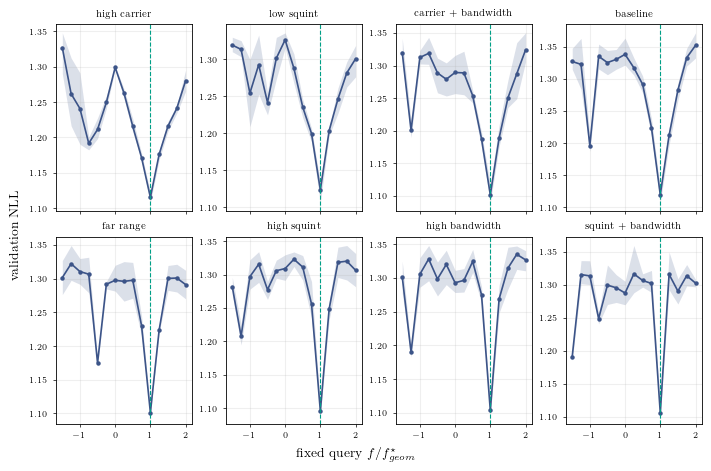

In [31]:
profile_names = PROFILE_SUMMARY["geometry"].tolist()
profile_columns = 4
profile_rows_count = int(np.ceil(len(profile_names) / profile_columns))
profile_figure, profile_axes = plt.subplots(
    profile_rows_count,
    profile_columns,
    figsize=(7.0, 2.3 * profile_rows_count),
    sharex=True,
    layout="constrained",
)
profile_axes = np.atleast_1d(profile_axes).ravel()
for axis, name in zip(profile_axes, profile_names):
    curve = PROFILE_CURVE_SUMMARY[
        PROFILE_CURVE_SUMMARY["geometry"] == name
    ].sort_values("query_ratio")
    axis.fill_between(
        curve["query_ratio"],
        curve["validation_nll_lower95"],
        curve["validation_nll_upper95"],
        color="#3C5488",
        alpha=0.18,
        linewidth=0,
    )
    axis.plot(
        curve["query_ratio"],
        curve["validation_nll"],
        color="#3C5488",
        marker="o",
        ms=2.2,
    )
    axis.axvline(1.0, color="#00A087", ls="--", lw=0.8)
    axis.set_title(name, fontsize=7)
    axis.grid(True, alpha=0.2)
for axis in profile_axes[len(profile_names) :]:
    axis.set_visible(False)
profile_figure.supxlabel(r"fixed query $f/f^\star_{geom}$")
profile_figure.supylabel("validation NLL")
plt.show()

## Supplementary figure: task mechanism

This figure shows the controlled mechanism without trained parameters. The geometry query is fixed across all scenes. The aligned gate removes the nonseparable target phase before the Fourier readout, whereas the equally entangling wrong-sign gate reinforces it. Averaging the readout conditional on the true class shows whether the geometry-selected representation makes the target cell directly accessible.

We pass 1024 scenes through the calibrated, untrained circuit for the three fixed queries, average the readout conditional on the true class, and take as example the first scene that the aligned circuit classifies correctly. The same random key gives a noiseless, clutter-free version of every scene for panel (a).

In [32]:
TASK_STAT_SCENES = 1024
TASK_ARMS = ("none", "mismatched", "aligned")
QUERY_LABELS = {
    "none": r"$f=0$",
    "mismatched": r"$f=-f^\star_{geom}$",
    "aligned": r"$f=f^\star_{geom}$",
}

def phase_rgb(patch, cmap=plt.get_cmap("twilight_shifted")):
    amplitude = np.abs(patch)
    amplitude = amplitude / max(amplitude.max(), 1e-30)
    rgb = cmap((np.angle(patch) + np.pi) / (2 * np.pi))[..., :3]
    return 1.0 - amplitude[..., None] * (1.0 - rgb)


task_key = jax.random.PRNGKey(seed_from(900))
ideal_signal, ideal_labels = scenes(
    task_key, TASK_STAT_SCENES, snr_db=60.0, n_clutter=0
)
task_signal, task_labels = scenes(task_key, TASK_STAT_SCENES)
assert np.array_equal(np.asarray(ideal_labels), np.asarray(task_labels))
task_phases = encode(task_signal)
task_labels_np = np.asarray(task_labels, dtype=int)
TASK_READOUT = {}
for arm in TASK_ARMS:
    query, learn = arm_setting(arm, F_GEOMETRY)
    TASK_READOUT[arm] = np.asarray(
        probabilities(CALIBRATION, task_phases, query, learn)
    )
CONDITIONAL_READOUT = {
    arm: np.stack(
        [p[task_labels_np == cls].mean(axis=0) for cls in range(Q)]
    )
    for arm, p in TASK_READOUT.items()
}
TASK_ACCURACY = {
    arm: balanced_accuracy(task_labels_np, np.argmax(p, axis=1))
    for arm, p in TASK_READOUT.items()
}

TASK_EXAMPLE = int(
    np.flatnonzero(
        np.argmax(TASK_READOUT["aligned"], axis=1) == task_labels_np
    )[0]
)
example_label = int(task_labels_np[TASK_EXAMPLE])
example_slice = slice(TASK_EXAMPLE, TASK_EXAMPLE + 1)
COMPRESSED = {}
for arm in TASK_ARMS:
    query, learn = arm_setting(arm, F_GEOMETRY)
    COMPRESSED[arm] = np.abs(
        np.asarray(
            circuit_state(
                CALIBRATION, task_phases[example_slice], query, learn
            )
        )[0]
    ) ** 2
    assert np.max(
        np.abs(
            COMPRESSED[arm].sum(axis=1)
            - TASK_READOUT[arm][TASK_EXAMPLE]
        )
    ) < 1e-10

Panel (a) shows the target alone, the delivered patch and the fixed query gate as phase images, with brightness encoding amplitude. Panel (b) shows the readout intensity of the example scene over azimuth cell $j$ and range $d$, and panel (c) the class-conditional readout with the balanced accuracy in each tile.

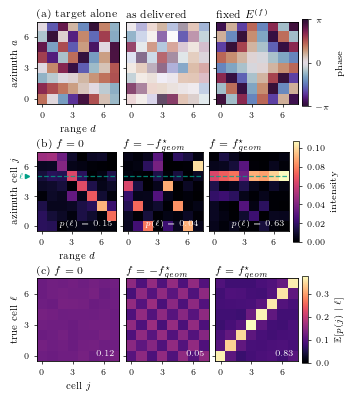

saved ../figures/fig_08_double_reuploading_geometry_task.pdf
{
  "example": 1,
  "label": 5,
  "fixed_query": 0.7930015007957375,
  "calibrated_accuracy": {
    "none": 0.119140625,
    "mismatched": 0.046875,
    "aligned": 0.8291015625
  }
}


In [33]:
fig = plt.figure(figsize=(3.375, 3.85), layout="constrained")
fig.get_layout_engine().set(h_pad=0.03, w_pad=0.02, hspace=0.03, wspace=0.02)
outer = fig.add_gridspec(3, 1, height_ratios=[1.0, 1.0, 1.0])
rows = [
    outer[index].subgridspec(1, 4, width_ratios=[1.0, 1.0, 1.0, 0.075])
    for index in range(3)
]


def style_tile(axis, first, xlabel, ylabel):
    axis.set_xticks([0, 3, 6])
    axis.set_yticks([0, 3, 6])
    axis.set_xlim(-0.5, Q - 0.5)
    axis.set_ylim(-0.5, Q - 0.5)
    if first:
        axis.set_xlabel(xlabel)
        axis.set_ylabel(ylabel)
    else:
        axis.set_yticklabels([])


# (a) ingredients
axes_a = [fig.add_subplot(rows[0][0, column]) for column in range(3)]
panels_a = [
    (np.asarray(ideal_signal[TASK_EXAMPLE]), "(a) target alone"),
    (np.asarray(task_signal[TASK_EXAMPLE]), "as delivered"),
    (np.exp(-1j * F_GEOMETRY * H_COMPACT), r"fixed $E^{(f)}$"),
]
for column, (axis, (patch, title)) in enumerate(zip(axes_a, panels_a)):
    axis.imshow(phase_rgb(patch), origin="lower", interpolation="nearest")
    axis.set_title(title, loc="left", pad=3)
    style_tile(axis, column == 0, r"range $d$", r"azimuth $a$")
phase_bar = fig.colorbar(
    mpl.cm.ScalarMappable(
        norm=mpl.colors.Normalize(-np.pi, np.pi),
        cmap=plt.get_cmap("twilight_shifted"),
    ),
    cax=fig.add_subplot(rows[0][0, 3]),
)
phase_bar.set_ticks([-np.pi, 0.0, np.pi])
phase_bar.set_ticklabels([r"$-\pi$", "0", r"$\pi$"])
phase_bar.set_label("phase", fontsize=6.5)
phase_bar.outline.set_linewidth(0.5)

# (b) one scene through the fixed readout
axes_b = [fig.add_subplot(rows[1][0, column]) for column in range(3)]
vmax_b = max(COMPRESSED[arm].max() for arm in TASK_ARMS)
for column, (axis, arm) in enumerate(zip(axes_b, TASK_ARMS)):
    image_b = axis.imshow(
        COMPRESSED[arm],
        origin="lower",
        cmap="magma",
        vmin=0.0,
        vmax=vmax_b,
        interpolation="nearest",
    )
    axis.set_title(
        ("(b) " if column == 0 else "") + QUERY_LABELS[arm],
        loc="left",
        pad=3,
    )
    axis.axhline(
        example_label,
        color=COLORS["geometry"],
        ls="--",
        lw=0.9,
        alpha=0.8,
    )
    if column == 0:
        axis.plot(
            -1.5,
            example_label,
            marker=">",
            ms=3.0,
            color=COLORS["geometry"],
            clip_on=False,
        )
        axis.annotate(
            r"$\ell$",
            xy=(-0.5, example_label),
            xytext=(-10.0, 0.0),
            textcoords="offset points",
            ha="right",
            va="center",
            color=COLORS["geometry"],
            fontsize=6.0,
            annotation_clip=False,
        )
    style_tile(axis, column == 0, r"range $d$", r"azimuth cell $j$")
    axis.text(
        0.96,
        0.04,
        rf"$p(\ell)={TASK_READOUT[arm][TASK_EXAMPLE][example_label]:.2f}$",
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        color="white",
        fontsize=5.8,
    )
intensity_bar = fig.colorbar(image_b, cax=fig.add_subplot(rows[1][0, 3]))
intensity_bar.set_label("intensity", fontsize=6.5)
intensity_bar.outline.set_linewidth(0.5)

# (c) conditional readout over the scene distribution
axes_c = [fig.add_subplot(rows[2][0, column]) for column in range(3)]
vmax_c = max(CONDITIONAL_READOUT[arm].max() for arm in TASK_ARMS)
for column, (axis, arm) in enumerate(zip(axes_c, TASK_ARMS)):
    image_c = axis.imshow(
        CONDITIONAL_READOUT[arm],
        origin="lower",
        cmap="magma",
        vmin=0.0,
        vmax=vmax_c,
        interpolation="nearest",
    )
    axis.set_title(
        ("(c) " if column == 0 else "") + QUERY_LABELS[arm],
        loc="left",
        pad=3,
    )
    style_tile(axis, column == 0, r"cell $j$", r"true cell $\ell$")
    axis.text(
        0.96,
        0.04,
        f"{TASK_ACCURACY[arm]:.2f}",
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        color="white",
        fontsize=5.8,
    )
conditional_bar = fig.colorbar(image_c, cax=fig.add_subplot(rows[2][0, 3]))
conditional_bar.set_label(r"$\mathbb{E} [p(j) \mid \ell]$", fontsize=6.5)
conditional_bar.outline.set_linewidth(0.5)

task_stem = FIGURE_DIR / f"{FIGURE_STEM}_task"
fig.savefig(task_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(task_stem.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.show()
print(f"saved {task_stem.with_suffix('.pdf')}")
print(
    json.dumps(
        {
            "example": TASK_EXAMPLE,
            "label": example_label,
            "fixed_query": F_GEOMETRY,
            "calibrated_accuracy": TASK_ACCURACY,
        },
        indent=2,
    )
)

## Figure

(a) Test balanced accuracy after fitting each fixed-query class $\mathcal H(f)$ on the same samples. (b) Validation-profile minimum $\widehat f$ against the geometry-derived $f^\star_{\rm geom}$ for each acquisition. (c) Sample efficiency of the aligned, trainable-query, wrong-sign and $x$-only circuits. Bands and error bars are 95% bootstrap intervals over independent paired scene draws.

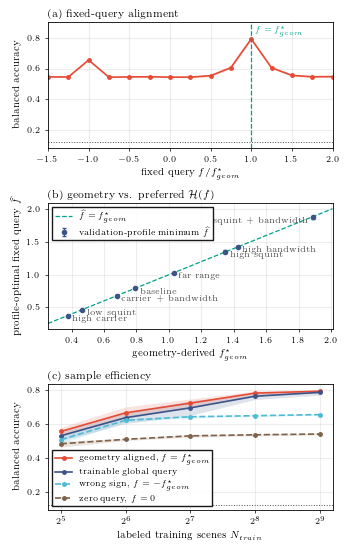

saved ../figures/fig_08_double_reuploading_geometry.pdf


In [34]:
LABELS = {
    "aligned": r"geometry aligned, $f=f^\star_{geom}$",
    "mismatched": r"wrong sign, $f=-f^\star_{geom}$",
    "none": r"zero query, $f=0$",
    "learned": "trainable global query",
}

fig = plt.figure(figsize=(3.375, 5.4), layout="constrained")
fig.get_layout_engine().set(h_pad=0.05, hspace=0.06)
axes = fig.subplots(3, 1)

# (a) fixed-query scan
axis = axes[0]
axis.fill_between(
    SCAN_X,
    SCAN_SUMMARY["lower"],
    SCAN_SUMMARY["upper"],
    color=COLORS["aligned"],
    alpha=0.20,
    linewidth=0,
)
axis.plot(
    SCAN_X,
    SCAN_SUMMARY["mean"],
    color=COLORS["aligned"],
    marker="o",
    ms=2.5,
)
axis.axvline(1.0, color=COLORS["geometry"], ls="--", lw=0.9)
axis.axhline(1.0 / Q, color=COLORS["reference"], ls=":", lw=0.7)
axis.annotate(
    r"$f=f^\star_{geom}$",
    xy=(1.0, 1.0),
    xycoords=("data", "axes fraction"),
    xytext=(2.5, -3),
    textcoords="offset points",
    color=COLORS["geometry"],
    fontsize=6.0,
    va="top",
)
peak_value = float(SCAN_SUMMARY["mean"].max())
axis.set_xlim(SCAN_X.min(), SCAN_X.max())
axis.set_xlabel(r"fixed query $f/f^\star_{geom}$")
axis.set_ylabel("balanced accuracy")
axis.set_title("(a) fixed-query alignment", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.set_ylim(1.0 / Q - 0.04, peak_value + 0.11)

# (b) fixed-query profile minimum for each acquisition
axis = axes[1]
predicted = PROFILE_SUMMARY["f_geometry"].to_numpy()
fitted = PROFILE_SUMMARY["f_hat"].to_numpy()
lower = fitted - PROFILE_SUMMARY["f_lower95"].to_numpy()
upper = PROFILE_SUMMARY["f_upper95"].to_numpy() - fitted
span = np.array(
    [min(predicted.min(), fitted.min()), max(predicted.max(), fitted.max())]
)
padding = 0.08 * max(span[1] - span[0], 1e-3)
span = np.array([span[0] - padding, span[1] + padding])
axis.plot(
    span,
    span,
    color=COLORS["geometry"],
    ls="--",
    lw=0.9,
    label=r"$\widehat f=f^\star_{geom}$",
)
axis.errorbar(
    predicted,
    fitted,
    yerr=np.vstack([lower, upper]),
    fmt="o",
    ms=3.0,
    color=COLORS["learned"],
    ecolor=COLORS["learned"],
    elinewidth=0.7,
    capsize=1.5,
    label=r"validation-profile minimum $\widehat f$",
)
axis.set_xlim(*span)

for x_value, y_value, name in zip(
    predicted, fitted, PROFILE_SUMMARY["geometry"]
):
    flip = x_value > span[0] + 0.7 * (span[1] - span[0])
    axis.annotate(
        name,
        xy=(x_value, y_value),
        xytext=(-3.0 if flip else 3.0, -4.5),
        textcoords="offset points",
        ha="right" if flip else "left",
        fontsize=5.8,
        color=COLORS["reference"],
    )
axis.set_xlabel(r"geometry-derived $f^\star_{geom}$")
axis.set_ylabel(r"profile-optimal fixed query $\widehat f$")
axis.set_title(r"(b) geometry vs. preferred $\mathcal{H}(f)$", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.legend(
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
    loc="upper left",
)

# (c) sample efficiency
axis = axes[2]
for arm in ("aligned", "learned", "mismatched", "none"):
    summary = EFFICIENCY_SUMMARY[arm]
    axis.fill_between(
        summary["n"],
        summary["lower"],
        summary["upper"],
        color=COLORS[arm],
        alpha=0.16,
        linewidth=0,
    )
    axis.plot(
        summary["n"],
        summary["mean"],
        color=COLORS[arm],
        marker="o",
        ms=2.5,
        ls="-" if arm in ("aligned", "learned") else "--",
        label=LABELS[arm],
    )
axis.axhline(1.0 / Q, color=COLORS["reference"], ls=":", lw=0.7)
axis.set_xscale("log", base=2)
axis.set_xlabel(r"labeled training scenes $N_{train}$")
axis.set_ylabel("balanced accuracy")
axis.set_title("(c) sample efficiency", loc="left", pad=3)
axis.grid(True, alpha=0.22)
axis.legend(
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
    loc="lower left",
)

figure_stem = FIGURE_DIR / FIGURE_STEM
fig.savefig(figure_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(figure_stem.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.show()
print(f"saved {figure_stem.with_suffix('.pdf')}")

## Summary

We write the key numbers behind the figure, together with the geometry, the validity checks, the efficiency curves and the per-acquisition profiles, to `results/sar_fixed_query/sar_fixed_query_summary_<PROFILE>_<RUN_ID>.json`, and print the paired accuracy differences of the aligned arm at every training-set size.

In [35]:
SUMMARY = {
    "profile": PROFILE,
    "run_id": RUN_ID,
    "geometry": GEOMETRY_SUMMARY,
    "validity": {
        key: (value if isinstance(value, (bool, np.bool_)) else float(value))
        for key, value in VALIDITY.items()
    },
    "audit": AUDIT,
    "calibrated_accuracy": TASK_ACCURACY,
    "efficiency": {
        arm: {
            "n": EFFICIENCY_SUMMARY[arm]["n"].tolist(),
            "mean": np.asarray(EFFICIENCY_SUMMARY[arm]["mean"]).tolist(),
            "lower95": np.asarray(EFFICIENCY_SUMMARY[arm]["lower"]).tolist(),
            "upper95": np.asarray(EFFICIENCY_SUMMARY[arm]["upper"]).tolist(),
        }
        for arm in ARMS
    },
    "geometry_profiles": PROFILE_SUMMARY.to_dict(orient="records"),
    "geometry_profile_curves": PROFILE_CURVE_SUMMARY.to_dict(
        orient="records"
    ),
    "geometry_profile_draw_minima": PROFILE_DRAW_MINIMA.to_dict(
        orient="records"
    ),
    "paired_effects_by_training_size": PAIRED_EFFECTS_BY_N.to_dict(
        orient="records"
    ),
    "scan_paired_advantage": SCAN_PAIRED_ADVANTAGE.to_dict(orient="records"),
}
summary_path = RESULTS_DIR / f"sar_fixed_query_summary_{PROFILE}_{RUN_ID}.json"
summary_path.write_text(json.dumps(SUMMARY, indent=2))

print(f"saved {summary_path}")
print(PAIRED_EFFECTS_BY_N.to_string(index=False))

saved ../results/sar_fixed_query/sar_fixed_query_summary_paper_0033ff2273a7.json
   control  n_train     mean   lower95  upper95
mismatched       32 0.048360  0.018061 0.079387
mismatched       64 0.043884  0.011189 0.080323
mismatched      128 0.080343  0.057534 0.104390
mismatched      256 0.133464  0.118673 0.147013
mismatched      512 0.138062  0.132202 0.144023
      none       32 0.072917  0.040709 0.106188
      none       64 0.156494  0.126585 0.188375
      none      128 0.193298  0.170125 0.217652
      none      256 0.246134  0.235413 0.256246
      none      512 0.252848  0.243693 0.258748
   learned       32 0.025350  0.007324 0.043437
   learned       64 0.028483 -0.000244 0.059431
   learned      128 0.028097  0.006591 0.054566
   learned      256 0.018453  0.003845 0.036052
   learned      512 0.006938 -0.001099 0.022461


## Scope and references

This is a controlled SAR-like spectral phase-history simulation with a phase-only feature map, not measured raw SAR data. It isolates one geometry-determined nonseparable phase interaction and tests whether fixing the corresponding non-absorbable query selects a useful hypothesis class. The result does not establish quantum advantage, state-preparation efficiency, or performance when the local bilinear approximation to the $\omega$-$k$ surface fails.

The wavenumber-domain construction follows the standard range-migration relation $k_y=\sqrt{k_r^2-k_x^2}$, for which Stolt interpolation maps the sampled $(k_x,k_r)$ data to a Cartesian wavenumber grid:

- B. Hosseiny *et al.*, “Range Migration Algorithm in the Processing Chain of Signals of a Ground-Based SAR Sensor,” *ISPRS Archives* XLII-4/W18, 521–525 (2019), [doi:10.5194/isprs-archives-XLII-4-W18-521-2019](https://doi.org/10.5194/isprs-archives-XLII-4-W18-521-2019).
- A. Reigber *et al.*, “Extended wavenumber-domain synthetic aperture radar focusing with integrated motion compensation,” *IEE Proc. Radar Sonar Navig.* 153, 301–310 (2006), [doi:10.1049/ip-rsn:20045087](https://doi.org/10.1049/ip-rsn:20045087).